# Plotting a `UgridDataset`

[`UgridDataset.plot`](index.md) draws a variable on an **unstructured mesh** (triangles / polygons) through cleopatra's mesh glyph, sharing the colour vocabulary of the raster path. This gallery plots a static mesh variable, styles it, adds a basemap, then animates a time-varying variable — and finishes on the `backend=` seam.

## Setup

Inline figures, imports, and the notebook-relative data path (one level deeper than the raster galleries).

In [1]:
%matplotlib inline
from pathlib import Path

from pyramids.netcdf.ugrid.dataset import UgridDataset
from pyramids.plot import ColorBar, ColorScaling, Contour, DataStyle

DATA = Path('../../../../examples/data')

Load a river-channel mesh with a CRS (EPSG:32631). It carries a static face variable `bathymetry` and a time-varying face variable `water_level`.

In [2]:
mesh = UgridDataset.read_file(str(DATA / 'river_channel_ugrid.nc'))
{name: (v.location, v.has_time, v.shape) for name, v in mesh.data_vars.items()}

{'bathymetry': ('face', False, (273,)),
 'water_level': ('face', True, (6, 273)),
 'velocity': ('node', False, (320,))}

## Quickstart

Name the variable; the mesh faces are coloured by its values.

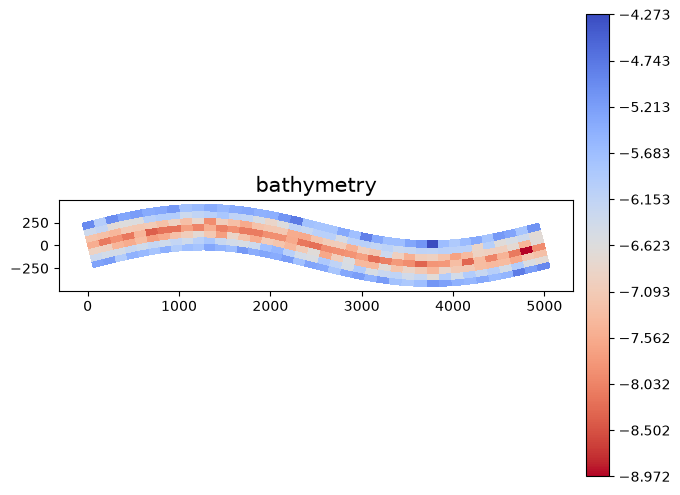

In [3]:
mesh.plot('bathymetry')

## Colormap: `cmap=`

A mesh takes a Matplotlib colormap name directly through `cmap`.

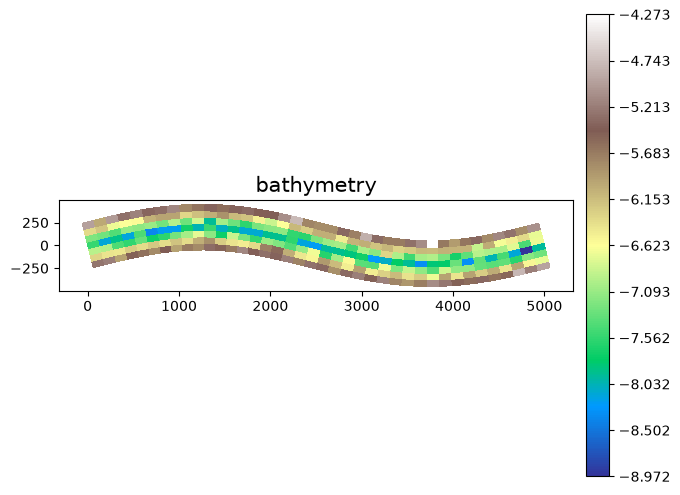

In [4]:
mesh.plot('bathymetry', cmap='terrain')

## Colour bar and scaling: `colorbar=` / `color=`

The same `ColorBar` and `ColorScaling` specs as the raster path apply to the mesh glyph.

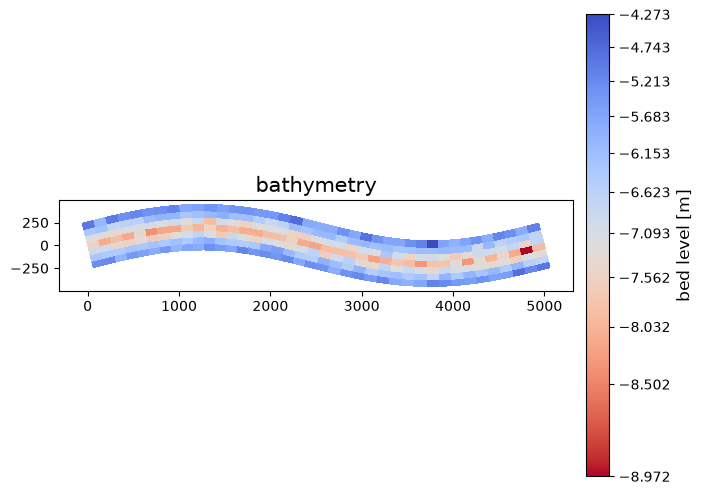

In [5]:
mesh.plot(
    'bathymetry',
    colorbar=ColorBar(label='bed level [m]'),
    color=ColorScaling.power(gamma=0.7),
)

## Contours: `contour=`

A `Contour` spec draws iso-lines across the mesh.

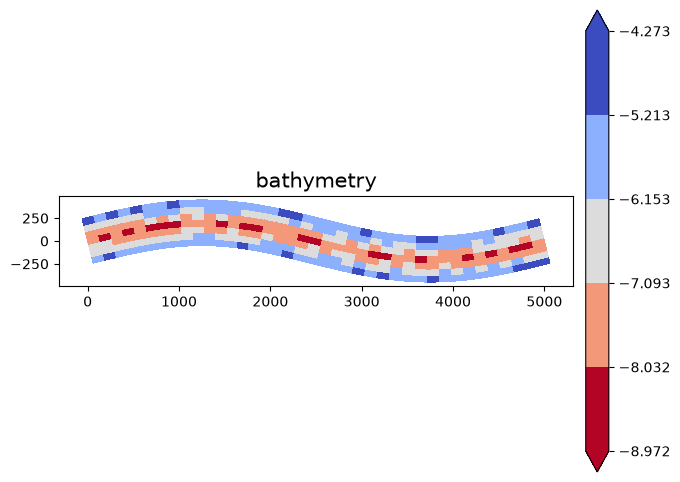

In [6]:
mesh.plot('bathymetry', contour=Contour(levels=6))

## Styling: `data_style=`

`DataStyle` applies a cleopatra styling preset to the mesh.

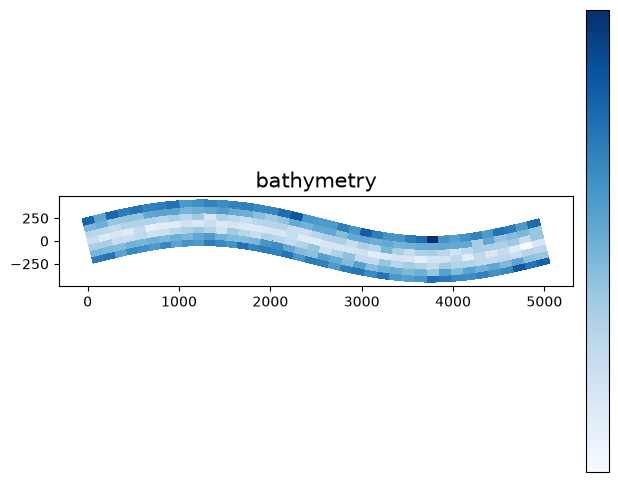

In [7]:
mesh.plot('bathymetry', data_style=DataStyle(style='flow_accumulation'))

## Basemap: `basemap=`

Because the mesh has a CRS, `basemap=True` can place a web-tile backdrop beneath it.

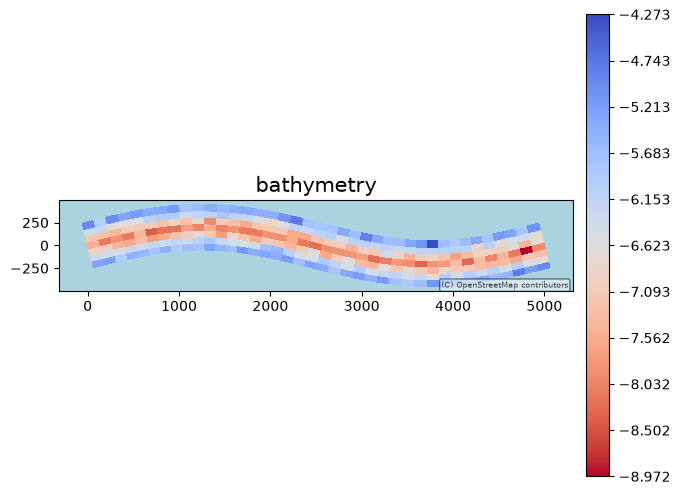

In [8]:
mesh.plot('bathymetry', basemap=True)

## A time-varying variable

Plotting a temporal variable draws its first time step; the colours now show water level rather than the bed.

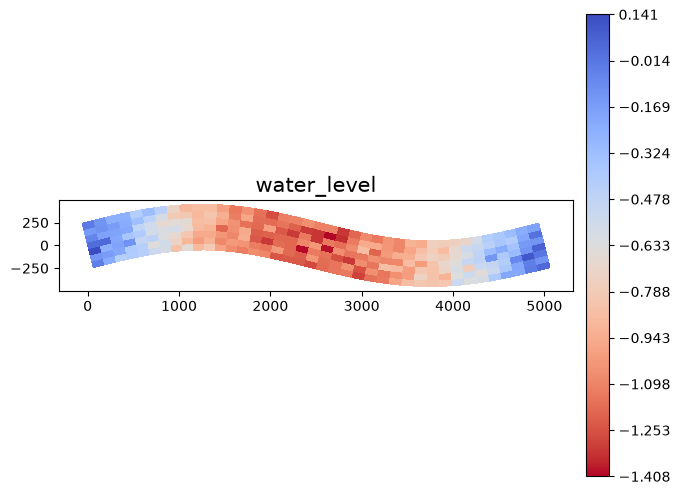

In [9]:
mesh.plot('water_level')

## Animation: `UgridDataset.animate(...)`

`animate` sweeps the variable over its time axis. For a mesh it returns a matplotlib `FuncAnimation` directly, which renders to an inline player.

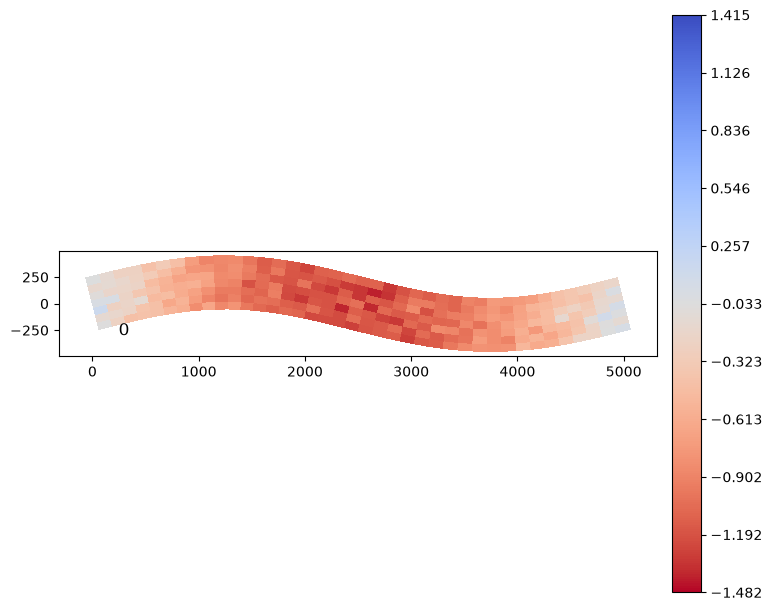

In [10]:
from IPython.display import HTML

anim = mesh.animate('water_level', interval=250)
HTML(anim.to_jshtml())

## Choosing a renderer with `backend=`

Every `plot` and `animate` method takes a keyword-only `backend=`. The default, `"matplotlib"`, draws through
[cleopatra](https://github.com/serapeum-org/cleopatra) — that is every figure above. Any other name is resolved at
call time through the `pyramids.plot_backends` entry-point group, with an optional fall-back to
[digitalearth](https://github.com/serapeum-org/Digital-Earth)'s richer tiers. pyramids declares **no dependency** on
any non-matplotlib renderer, so a bare install always plots through matplotlib.

| `backend=` | Renderer | Install |
|---|---|---|
| `"matplotlib"` (default) | cleopatra / matplotlib — static figures | included with the `[viz]` extra |
| `"interactive"` | digitalearth (HoloViz / Bokeh) | `pip install 'digitalearth[interactive]'` |
| `"3d"` | digitalearth (PyVista) | `pip install 'digitalearth[3d]'` |
| `"web"` | digitalearth (MapLibre / deck.gl) | `pip install 'digitalearth[web]'` |

Stating the default explicitly produces exactly the quickstart figure; the digitalearth tiers follow:

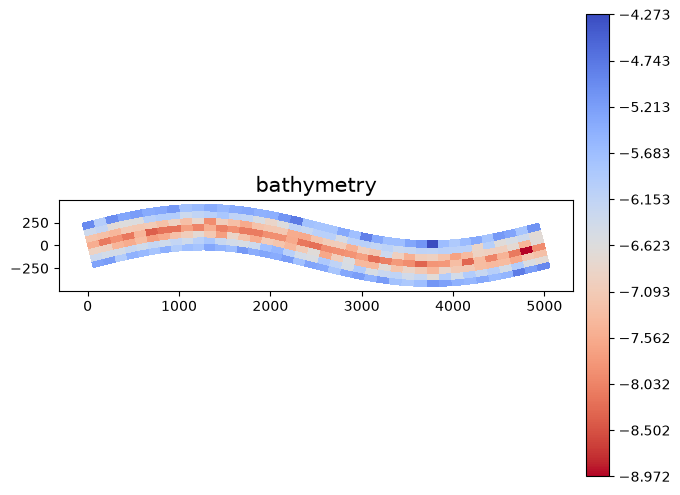

In [11]:
mesh.plot('bathymetry', backend='matplotlib')

### The digitalearth tiers today

digitalearth's `interactive` / `3d` / `web` renderers draw **raster** inputs. A `UgridDataset` is an unstructured mesh, which
digitalearth 0.13 does not yet accept through `quickmap`, so those backends are not shown here — see the
[Dataset gallery](../dataset/plotting-gallery.ipynb) for live interactive, web and 3-D output on a raster.
Wiring `UgridDataset` support into digitalearth is upstream work in the
[digitalearth repo](https://github.com/serapeum-org/Digital-Earth); until it lands, `UgridDataset.plot` renders through
matplotlib (every figure above). The `backend=` seam itself is ready — it already resolves and dispatches to
digitalearth the moment digitalearth supports the input type.

## Takeaway

`UgridDataset.plot` brings the raster colour vocabulary to unstructured meshes — colormap, colour bar, scaling, contours, styling and basemaps — and `animate` turns a temporal mesh variable into a movie, all routable through `backend=`.